# TRABAJO PRACTICO INTEGRADOR - SEGUNDO PARCIAL
#### INTEGRANTES:
- Bianciotto Sofia - 1241171
- Cebreiros Juana - 1238673
- Lacava Giuliana - 1239334
- Lazaro Martina - 1238503
##### TEMA: Utilizaremos un dataset de una veterinaria, con el objetivo de predecir un diagnostico segun las variables dadas.

### PARTE 1 - CARGA DE DATOS

HACER:
- ver de transformar booking date e intake date a date (esta como string)
- ver de transformar patient ID a str (esta como int)
- averiguar si las fachas que faltan en booking date son por falta de registro, o porque llegaron de emergencia. 
- ver si se puede agregar algun registro duplicado, para trabajar con la visualizacion y eliminacion (dsp se borra el duplicado, asique no afectaria el analisis original)
- ver que columnas elimino por nulos, y ver cuales puedo imputar por la media o mediana (o moda)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("Vet_Clinical_Dataset.csv")
print("el Dataset fue cargado exitosamente. Tiene las siguientes dimensiones:")
df.shape

el Dataset fue cargado exitosamente. Tiene las siguientes dimensiones:


(2000, 15)

### PARTE 2 - EDA INICIAL - PREPARACIÓN Y LIMPIEZA DE DATOS

En los siguientes cuadros de codigo, revisaremos el dataset y los datos del mismo, verificando si hay valores nulos, duplicados, faltantes. Luego analizaremos que hacer frente a cada problema encontrado. 

In [3]:
df.columns

Index(['Patient ID', 'ownership_status', 'intake date', 'booking date',
       'species', 'breed', 'age', 'sex', 'weight', 'temperature', 'heart rate',
       'intake location', 'Body condition score', 'wood lamp fungal',
       'definitive diagnosis'],
      dtype='str')

Que informacion nos da cada columna:
- Patitient ID: codigo de identificacion unico para cada caso. 
- ownership_status: origen del animal (owned - recued - lost_rescued)
- intake date: fecha en que el animal fue llevado a la consulta para la evaluacion clinica
- booking date: fecha de una consulta con reserva previa
- intake location: area geografica (en la ciudad de Makati)
- species: tipo de animal
- breed: clasificacion de raza
- age: edad del paciente
- sex: genero del paciente
- weight: peso del paciente (en kg)
- temperature: temperatura corporal al ingreso a la consulta (en grados Celsius)
- heart rate: latidos por minuto
- body condition score: condicion corporal en una escala del 1 (escualido) al 9 (obesidad)
- wood lamp fungal: test para detectar infecciones (positive - negative)
- definitive diagnosis: el diagnostico final dictado por el veterinario de turno

In [4]:
df.head(3) #primero 3 registros del dataset


,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
0,25021825,rescued,2/28/2025,NaN,canine,Aspin,4 years,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis
1,23110410,owned,NaN,11/13/2023,canine,Shih Tzu,9 years,male,9.7,39.1,NaN,NaN,4.0,Negative,Atopic Dermatitis
2,23124507,owned,NaN,12/2/2023,canine,Golden Retriever,12 weeks,male,11.7,39.1,NaN,NaN,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis


In [5]:
df.tail(3) #ultimos 3 registros del dataset

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
1997,24124383,rescued,12/18/2024,NaN,canine,Aspin,11 weeks,male,4.0,39.2,NaN,"Urdaneta, Makati City",4.0,Positive,Ringworm
1998,24127367,rescued,12/19/2024,NaN,feline,Puspin,10 years,female,5.0,38.1,196.0,"San Lorenzo, Makati City",7.0,Negative,Bacterial Dermatitis and Bacterial Otitis
1999,24034062,rescued,3/15/2024,NaN,feline,Siamese,12 weeks,female,2.0,38.3,NaN,"Bel-Air, Makati City",7.0,Negative,Ear Mites and Yeast Otitis


In [6]:
df.sample(5) #5 registros aleatorios del datset

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
725,25116659,lost_rescued,11/11/2025,NaN,canine,Siberian Husky,8 years,male,23.1,39.1,91.0,"San Lorenzo, Makati City",3.0,Negative,Ear Mites
1638,23098240,owned,NaN,9/26/2023,canine,Siberian Husky,8 months,male,20.6,38.9,97.0,NaN,3.0,Negative,healthy
1846,25122256,rescued,12/27/2025,NaN,canine,Aspin,5 years,female,6.9,39.0,101.0,"San Lorenzo, Makati City",3.0,Positive,Ringworm and Yeast Otitis
1115,24073589,lost_rescued,7/15/2024,NaN,feline,Siamese,8 years,male,3.1,39.2,164.0,"Palanan, Makati City",3.0,Negative,Yeast Dermatitis
1501,25105296,owned,NaN,10/17/2025,feline,British Shorthair,3 years,male,6.2,38.9,203.0,NaN,4.0,Negative,Atopic Dermatitis


In [7]:
df.info() #panorama general del dataset. cantidad de filas, columnas, nombres de las columnas, cantidad de valores no nulos por columna y tipo de dato de cada columna.

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Patient ID            2000 non-null   int64  
 1   ownership_status      2000 non-null   str    
 2   intake date           866 non-null    str    
 3   booking date          1134 non-null   str    
 4   species               2000 non-null   str    
 5   breed                 2000 non-null   str    
 6   age                   2000 non-null   str    
 7   sex                   2000 non-null   str    
 8   weight                2000 non-null   float64
 9   temperature           2000 non-null   float64
 10  heart rate            1689 non-null   float64
 11  intake location       866 non-null    str    
 12  Body condition score  1942 non-null   float64
 13  wood lamp fungal      2000 non-null   str    
 14  definitive diagnosis  2000 non-null   str    
dtypes: float64(4), int64(1), str(10)

podemos observar que el datset contiene 2000 filas y 15 columnas, de las cuales 10 no tienen ningun valor nulo. "intake date" - "booking date" - "heart rate" - "intake location" - "body condition score" tienen valores nulos. 

In [8]:
df.describe() #resmen estadistico de las variables numericas

,Patient ID,weight,temperature,heart rate,Body condition score
count,2.000000e+03,2000.000000,2000.000000,1689.000000,1942.000000
mean,2.404418e+07,7.652150,38.711250,129.512729,4.845520
std,8.212429e+05,7.340566,0.294859,41.831217,1.453319
min,2.301009e+07,0.700000,38.000000,66.000000,3.000000
25%,2.309690e+07,3.100000,38.500000,96.000000,3.000000
50%,2.406290e+07,4.500000,38.700000,115.000000,5.000000
75%,2.503390e+07,9.700000,39.000000,165.000000,6.000000
max,2.512987e+07,35.800000,39.300000,230.000000,7.000000


- count: cantidad de valores no nulos
- mean: promedio
- std: desvio estandar
- min: valor minimo 
- 25% - 75%: primer y tercer cuartil
- 50%: mediana
- max: valor maximo

observaciones:
- "heart rate" y "body condition score" tiene valores nulos 
- este no es un analisis significativo para la variable Patient ID, ya que es una variable unica de cada paciente. Serviria mas analizarla como "object". (ver de hacer una transformacion a object)
- en "weight" y "heart rate" el promedio se encuentra alejado del valor de la media, tienen un desvio estandar elevado, por lo que los datos estan dispersos. Puede significar la presencia de algun outlier.

In [9]:
df.describe(include="object") #ahora aplicado a las variables categoricas 

C:\Users\bianc\AppData\Local\Temp\ipykernel_23032\2804790000.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object") #ahora aplicado a las variables categoricas


,ownership_status,intake date,booking date,species,breed,age,sex,intake location,wood lamp fungal,definitive diagnosis
count,2000,866,1134,2000,2000,2000,2000,866,2000,2000
unique,3,586,678,2,13,26,2,16,2,13
top,owned,9/24/2024,2023-05-08,canine,Aspin,11 months,female,"South Cembo, Makati City",Negative,Ear Mites and Yeast Otitis
freq,1134,4,6,1199,484,131,1008,69,1683,181


- count: valores no nulos
- unique: cantidad de valores unicos
- top: valor mas frecuete
- freq: frecuencia del valor mas frecuente

observaciones: 
- sobre "ownership status":     
        - el valor mas repetido es "owned" apareciendo 1134 veces de 2000 registros totales, lo que significa que al menos de la mitad de los animmales atendidos tenian dueño. 
- sobre "intake date":
       - hay varios valores faltantes, de 2000 ingresos, solo se registraron 866 en esta categoria. las fechas de ingreso estan muy distribuidas, no existe una en particular que acumule un gran porcentaje de animales ingresados. 
- sobre "booking date":
        - lo mismo que para la variable anterior, muchos datos faltantes 
- sobre "species":
        - hay solamente 2 tipos de especies, siendo apenas mas de la mitad "canine"
- sobre "breed":
        - hay 13 razas diferentes, siendo "Aspin" la as frecuente, representando el 24,2% de los registros
- sobre "age":
        - de 26 edades registradas, ninguna representa una gran mayoria de los datos. 
- sobre "sex":
        - el sexo femenino esta muy levemente mas repetido que el sexo masculino (los dos unicos valores posibles)
- sobre "intake location":
        - ninguna de las 16 ubicaciones esta mucho mas repetida que el resto. hay que considerar que hay mas de la mitad de valores faltantes
- sobre "wood lamp fungal":
        - la mayoria de los resultados dio negativo (el 84,15%). solo el 15,85% dio positivo. todos los animales se fueron sometidos  este test.
- sobre "definitive diagnosis":
        - hubo 13 diagnosticos distintos, el mas repetido "ear mites and yeast otitis", sin predominar ampliamente por sobre el resto

In [10]:
df.describe(include="all") #esta es la forma de incluir lo de ambas tablas anteriores en una sola

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
count,2.000000e+03,2000,866,1134,2000,2000,2000,2000,2000.000000,2000.000000,1689.000000,866,1942.000000,2000,2000
unique,NaN,3,586,678,2,13,26,2,NaN,NaN,NaN,16,NaN,2,13
top,NaN,owned,9/24/2024,2023-05-08,canine,Aspin,11 months,female,NaN,NaN,NaN,"South Cembo, Makati City",NaN,Negative,Ear Mites and Yeast Otitis
freq,NaN,1134,4,6,1199,484,131,1008,NaN,NaN,NaN,69,NaN,1683,181
mean,2.404418e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.652150,38.711250,129.512729,NaN,4.845520,NaN,NaN
std,8.212429e+05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.340566,0.294859,41.831217,NaN,1.453319,NaN,NaN
min,2.301009e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.700000,38.000000,66.000000,NaN,3.000000,NaN,NaN
25%,2.309690e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.100000,38.500000,96.000000,NaN,3.000000,NaN,NaN
50%,2.406290e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.500000,38.700000,115.000000,NaN,5.000000,NaN,NaN
75%,2.503390e+07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.700000,39.000000,165.000000,NaN,6.000000,NaN,NaN


In [11]:
df["ownership_status"].value_counts()

ownership_status
owned           1134
rescued          684
lost_rescued     182
Name: count, dtype: int64

de 2000 animales: 56,7% tenian dueño - 32,4% fueron rescatados - 9,1% fueron "lost_rescued"

In [12]:
df["breed"].value_counts() #cuantos ingresos de cada raza

breed
Aspin                 484
Puspin                342
Persian               121
Domestic Shorthair    120
Siberian Husky        113
Chihuahua             110
British Shorthair     109
Siamese               109
French Bulldog        109
Shih Tzu              102
Golden Retriever       98
Pomeranian             93
Poodle                 90
Name: count, dtype: int64

In [13]:
df["intake location"].value_counts() #cuantos ingresos por cada ubicacion

intake location
South Cembo, Makati City            69
Palanan, Makati City                64
Pitogo, Makati City                 64
Urdaneta, Makati City               62
Bel-Air, Makati City                56
Guadalupe Nuevo, Makati City        56
East Rembo, Makati City             55
Pembo, Makati City                  54
San Lorenzo, Makati City            53
Guadalupe Viejo, Makati City        53
Makati Central Business District    51
Rizal, Makati City                  49
West Rembo, Makati City             47
Comembo, Makati City                46
Poblacion, Makati City              46
San Antonio, Makati City            41
Name: count, dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

no hay ningun registro con exactamente los mismos valores en todas sus columnas.

In [15]:
df.isnull().sum() #nos muestra los valores nulos por columna

Patient ID                 0
ownership_status           0
intake date             1134
booking date             866
species                    0
breed                      0
age                        0
sex                        0
weight                     0
temperature                0
heart rate               311
intake location         1134
Body condition score      58
wood lamp fungal           0
definitive diagnosis       0
dtype: int64

Podemos observar:
- "intake date" tiene 1134 valores nulos.
- "booking date" tiene 866 valores nulos.
- "heart rate" tiene 311 valores nulos.
- "intake location" tiene 1134 valores nulos. 
- "body condition score" tiene 58 valores nulos.
- todo el resto de las columnas no tiene valores nulos. 

In [16]:
nulos_porcentaje = df.isnull().sum() / (len(df)) * 100

print(nulos_porcentaje) #nos muestra el porcentaje de datos nulos por columna

Patient ID               0.00
ownership_status         0.00
intake date             56.70
booking date            43.30
species                  0.00
breed                    0.00
age                      0.00
sex                      0.00
weight                   0.00
temperature              0.00
heart rate              15.55
intake location         56.70
Body condition score     2.90
wood lamp fungal         0.00
definitive diagnosis     0.00
dtype: float64


In [17]:
df[df.isnull().any(axis=1)] #visualizacion de registros con al menos 1 dato faltante

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis
0,25021825,rescued,2/28/2025,NaN,canine,Aspin,4 years,male,6.7,39.1,114.0,"East Rembo, Makati City",4.0,Negative,Bacterial Dermatitis and Bacterial Otitis
1,23110410,owned,NaN,11/13/2023,canine,Shih Tzu,9 years,male,9.7,39.1,NaN,NaN,4.0,Negative,Atopic Dermatitis
2,23124507,owned,NaN,12/2/2023,canine,Golden Retriever,12 weeks,male,11.7,39.1,NaN,NaN,3.0,Negative,Bacterial Dermatitis and Bacterial Otitis
3,23014013,owned,NaN,2023-01-07,feline,Puspin,12 years,female,4.1,38.7,NaN,NaN,3.0,Negative,Ear Mites and Yeast Otitis
4,24073658,rescued,7/17/2024,NaN,canine,Aspin,3 years,female,8.1,39.0,79.0,"Comembo, Makati City",3.0,Negative,Ear Mites
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,25097643,owned,NaN,2025-09-02,canine,Aspin,9 months,female,13.3,39.0,104.0,NaN,7.0,Negative,Bacterial Dermatitis
1996,23052008,rescued,5/20/2023,NaN,canine,French Bulldog,7 years,female,22.0,38.9,NaN,Makati Central Business District,5.0,Negative,Atopic Dermatitis
1997,24124383,rescued,12/18/2024,NaN,canine,Aspin,11 weeks,male,4.0,39.2,NaN,"Urdaneta, Makati City",4.0,Positive,Ringworm
1998,24127367,rescued,12/19/2024,NaN,feline,Puspin,10 years,female,5.0,38.1,196.0,"San Lorenzo, Makati City",7.0,Negative,Bacterial Dermatitis and Bacterial Otitis


In [18]:
df1 = df.dropna()

df1.shape

(0, 15)

In [19]:
df1.head()

,Patient ID,ownership_status,intake date,booking date,species,breed,age,sex,weight,temperature,heart rate,intake location,Body condition score,wood lamp fungal,definitive diagnosis


## Agrupaciones y Visualizaciones:
En esta sección analizaremos los datos agrupados por especie y sexo, estudiaremos los diagnósticos más frecuentes y evaluaremos la viabilidad de una serie temporal.

In [20]:
#agrupacion de datos cruzando las columnas "definitive diagnosis", "species" y "sex"
resumen_cruzado = df.groupby(["definitive diagnosis", "species", "sex"]).agg(
    total_casos=('Patient ID', 'count'),
    peso_promedio=('weight', 'mean'),
    temp_promedio=('temperature', 'mean'),
    bcs_promedio=('Body condition score', 'mean')
).reset_index()

# Mostramos el resultado ordenado por los que tienen más casos
display(resumen_cruzado.sort_values(by='total_casos', ascending=False).head(10))

,definitive diagnosis,species,sex,total_casos,peso_promedio,temp_promedio,bcs_promedio
8,Bacterial Dermatitis,canine,female,66,9.781818,38.769697,5.107692
5,Atopic Dermatitis and Bacterial Otitis,canine,male,59,11.205085,38.783051,4.982759
33,Ringworm and Yeast Otitis,canine,male,59,11.889831,38.686441,4.962264
24,Ear Mites and Yeast Otitis,canine,female,55,10.092727,38.754545,4.962963
29,Ringworm,canine,male,55,7.276364,38.745455,5.327273
25,Ear Mites and Yeast Otitis,canine,male,52,11.592308,38.725000,4.666667
37,Yeast Dermatitis,canine,male,51,11.049020,38.813725,5.180000
41,Yeast Dermatitis and Yeast Otitis,canine,male,51,9.950980,38.749020,4.760000
17,Bacterial Otitis,canine,male,51,10.041176,38.739216,4.666667
20,Ear Mites,canine,female,50,11.378000,38.814000,5.306122


### Gráfico de distribución de diagnósticos
A continuación, visualizamos la frecuencia de los diagnósticos definitivos comparados entre especies para detectar patrones relevantes:

<Figure size 1100x600 with 0 Axes>

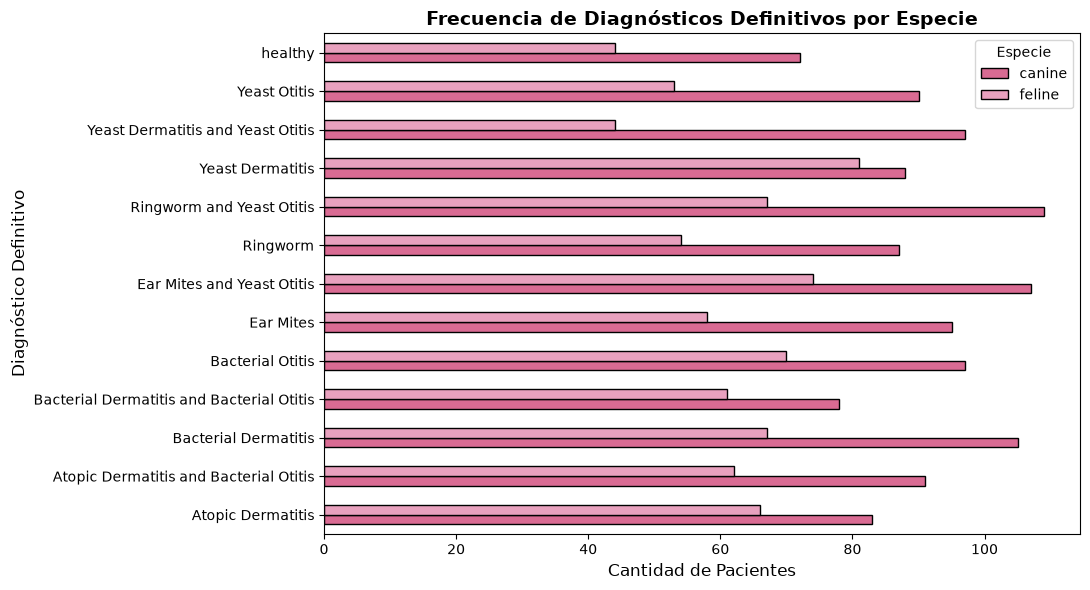

In [21]:
import matplotlib.pyplot as plt
#Tabla cruzada de diagnósticos definitivos según la especie
diag_especie = pd.crosstab(df['definitive diagnosis'], df['species'])

#grafico de barras apiladas para visualizar la distribución de diagnósticos por especie
plt.figure(figsize=(11, 6))
diag_especie.plot(kind='barh', figsize=(11, 6), color=['#d96b93', '#e8a1be'], edgecolor='black')
plt.title('Frecuencia de Diagnósticos Definitivos por Especie', fontsize=14, fontweight='bold')
plt.xlabel('Cantidad de Pacientes', fontsize=12)
plt.ylabel('Diagnóstico Definitivo', fontsize=12)
plt.legend(title='Especie')
plt.tight_layout()
plt.show()

**Objetivo**: predecir si un paciente esta **sano** o **enfermo** a partir de sus datos clinicos usando **k-NN**, y justificar que **variables predictoras** conviene usar.

### Decisiones de diseño (y por qué)

1. **Variable objetivo = sano / enfermo.** Es la misma variable `estado_salud` que se usó en el EDA. Con los 13 diagnósticos por separado el modelo casi no mejora el azar (se muestra en el *Anexo* al final).
2. **Las clases están muy desbalanceadas** (≈ 94 % enfermos). Un modelo que diga "enfermo" siempre acertaría el 94 %. Por eso **no alcanza con el accuracy**: usamos **F1 macro**, **balanced accuracy** y miramos el **recall de la clase "sano"** 
3. **Rehacemos la preparación desde el CSV** en vez de usar el `df` de la Parte 2, por dos motivos:
   - la Parte 2 imputa los nulos **antes** de separar train y test (el test "se filtra" en la mediana);
   - la frecuencia cardíaca se imputó con la **mediana global (115 lpm)**, mezclando caninos y felinos. La propia Parte 2 dejó la nota *"ver de separar heart rate según canino o felino"*. Acá la imputación se hace **después del split, con la mediana de train y por especie**.
4. **Se descarta `intake location`**: es nula *exactamente* cuando el animal tiene dueño (`owned`), así que repite la información de `ownership_status`.

In [22]:
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEMILLA = 42
ROSA, ROSA_CLARO = "#d96b93", "#e8a1be"   # misma paleta que la Parte 2

# 1. Preparación de los datos

Partimos del CSV original. Se hace lo mismo que en la Parte 2 (sacar `Patient ID` y las fechas, pasar `age` a años), más la codificación numérica que necesita KNN para calcular distancias:

- `species`, `sex`, `wood lamp fungal` → 0/1.
- `ownership_status` (3 categorías sin orden) → dos columnas 0/1 (`rescued`, `lost_rescued`; `owned` es cuando ambas valen 0).
- `heart rate` y `Body condition score` **conservan sus nulos** por ahora: se imputan recién después del split.

In [23]:
raw = pd.read_csv("Vet_Clinical_Dataset.csv")

def convertir_edad(edad):
    '''Pasa "12 weeks" / "9 months" / "4 years" a edad en años (float).'''
    numero, unidad = edad.split()
    numero = float(numero)
    if unidad.startswith("year"):
        return numero
    if unidad.startswith("month"):
        return numero / 12
    return numero / 52   # weeks

df_ml = pd.DataFrame({
    "diagnostico": raw["definitive diagnosis"],
    "estado": np.where(raw["definitive diagnosis"] == "healthy", "sano", "enfermo"),
    "edad": raw["age"].apply(convertir_edad),
    "peso": raw["weight"],
    "temperatura": raw["temperature"],
    "frec_cardiaca": raw["heart rate"],                    # conserva sus nulos
    "condicion_corporal": raw["Body condition score"],     # conserva sus nulos
    "felino": (raw["species"] == "feline").astype(int),    # 1 = felino, 0 = canino
    "macho": (raw["sex"] == "male").astype(int),
    "wood_positivo": (raw["wood lamp fungal"] == "Positive").astype(int),
    "rescued": (raw["ownership_status"] == "rescued").astype(int),
    "lost_rescued": (raw["ownership_status"] == "lost_rescued").astype(int),  # owned = ambas en 0
})

# Columnas auxiliares solo para describir (no van al modelo)
df_ml["especie"] = np.where(df_ml["felino"] == 1, "felino", "canino")
df_ml["tenencia"] = np.select([df_ml["rescued"] == 1, df_ml["lost_rescued"] == 1],
                              ["rescued", "lost_rescued"], default="owned")

# Raza en formato 0/1 (se usa más adelante solo para comprobar si aporta algo)
RAZAS = pd.get_dummies(raw["breed"], prefix="raza").astype(int)

print(df_ml.shape)
df_ml.head()

(2000, 14)


,diagnostico,estado,edad,peso,temperatura,frec_cardiaca,condicion_corporal,felino,macho,wood_positivo,rescued,lost_rescued,especie,tenencia
0,Bacterial Dermatitis and Bacterial Otitis,enfermo,4.000000,6.7,39.1,114.0,4.0,0,1,0,1,0,canino,rescued
1,Atopic Dermatitis,enfermo,9.000000,9.7,39.1,NaN,4.0,0,1,0,0,0,canino,owned
2,Bacterial Dermatitis and Bacterial Otitis,enfermo,0.230769,11.7,39.1,NaN,3.0,0,1,0,0,0,canino,owned
3,Ear Mites and Yeast Otitis,enfermo,12.000000,4.1,38.7,NaN,3.0,1,0,0,0,0,felino,owned
4,Ear Mites,enfermo,3.000000,8.1,39.0,79.0,3.0,0,0,0,1,0,canino,rescued


# 2. Verificación de los patrones "demasiado marcados"

Antes de elegir variables, comprobamos lo que advirtió el equipo en el EDA: si los patrones tan nítidos son reales o consecuencia de cómo se armó el dataset.

### 2.1 Los nulos no son aleatorios

In [24]:
nulos = df_ml[["frec_cardiaca", "condicion_corporal"]].isna().groupby(df_ml["estado"]).sum()
nulos["total_pacientes"] = df_ml["estado"].value_counts()
nulos

,frec_cardiaca,condicion_corporal,total_pacientes
estado,,,
enfermo,311,58,1884
sano,0,0,116


**Todos** los nulos de frecuencia cardíaca y de condición corporal están en pacientes **enfermos**; entre los 116 sanos no falta ni un dato. No hay una razón clínica para eso: es una característica del dataset.

Consecuencia: **no usamos "el dato falta" como predictor** (sería una fuga: el modelo aprendería *"si no hay frecuencia cardíaca → enfermo"*). Los nulos se imputan, y se hace **por especie**, porque como se ve a continuación caninos y felinos tienen escalas muy distintas.

### 2.2 Frecuencia cardíaca: ¿por qué imputar por especie?

count    min  median    max
especie estado                              
canino  enfermo    929   66.0   103.0  137.0
        sano        72   73.0    95.0  117.0
felino  enfermo    644  138.0   174.0  230.0
        sano        44   75.0    93.5  117.0

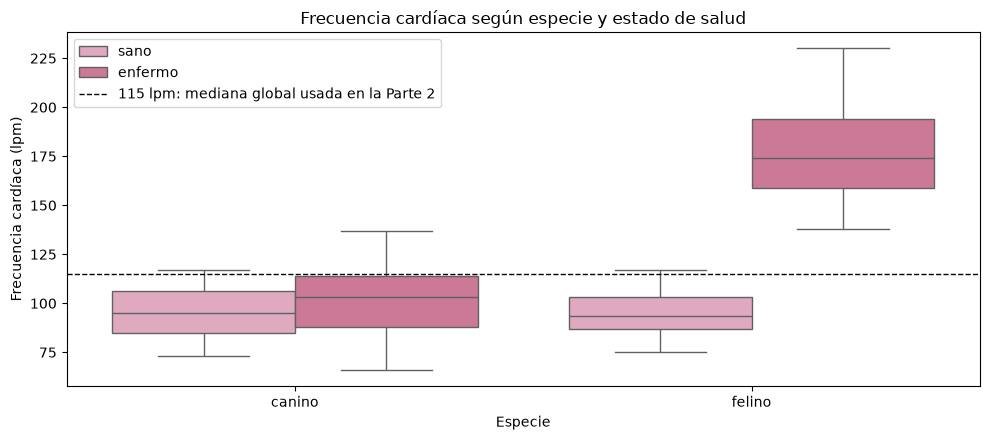

Felinos enfermos con frecuencia cardíaca nula: 113


In [25]:
display(df_ml.groupby(["especie", "estado"])["frec_cardiaca"].agg(["count", "min", "median", "max"]))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.boxplot(data=df_ml, x="especie", y="frec_cardiaca", hue="estado",
            hue_order=["sano", "enfermo"], palette={"sano": ROSA_CLARO, "enfermo": ROSA}, ax=ax)
ax.axhline(115, color="black", linestyle="--", linewidth=1,
           label="115 lpm: mediana global usada en la Parte 2")
ax.set_title("Frecuencia cardíaca según especie y estado de salud")
ax.set_xlabel("Especie")
ax.set_ylabel("Frecuencia cardíaca (lpm)")
ax.legend()
plt.tight_layout()
plt.show()

felinos_enfermos_nulos = ((df_ml["especie"] == "felino") & (df_ml["estado"] == "enfermo") & df_ml["frec_cardiaca"].isna()).sum()
print(f"Felinos enfermos con frecuencia cardíaca nula: {felinos_enfermos_nulos}")

Lo que se ve:

- **Imputar con 115 lpm es un error para los felinos.** Los felinos enfermos tienen entre 138 y 230 lpm, y los sanos entre 75 y 117. Poner 115 a los 113 felinos enfermos con dato faltante los hace parecer **sanos**. Por eso imputamos con la mediana **de cada especie**.
- **Dato sospechoso:** los sanos de las dos especies tienen la misma frecuencia (≈ 95 lpm, rango 73-117). En la práctica veterinaria, los valores de referencia habituales para un gato sano son bastante más altos (del orden de 140-220 lpm), es decir, **justo el rango que en este dataset tienen los felinos enfermos**. Un gato "sano" con 95 lpm sería clínicamente raro. No podemos afirmarlo solo con los datos, pero todo indica que la separación casi perfecta en felinos es una **consecuencia de cómo se generó el dataset** (a los sanos se les asignó el mismo rango sin importar la especie) y no un hallazgo veterinario. Sirve como señal para el modelo, pero conviene aclararlo en las conclusiones.

### 2.3 Condición corporal

In [26]:
(pd.crosstab(df_ml["estado"], df_ml["condicion_corporal"], normalize="index") * 100).round(1)

condicion_corporal,3.0,4.0,5.0,6.0,7.0
estado,,,,,
enfermo,21.3,19.3,20.8,19.2,19.5
sano,100.0,0.0,0.0,0.0,0.0


Los **116 sanos tienen puntaje 3, sin excepción**, y los enfermos se reparten casi parejo entre 3 y 7 (≈ 20 % cada uno). Dos cosas poco naturales: (1) en la escala de 1 a 9 el puntaje ideal ronda 4-5, no 3 (que ya es delgadez); (2) una distribución uniforme en enfermos es poco realista. Otra vez parece un patrón de **construcción del dataset**.

Para el modelo es una señal fuerte (puntaje ≥ 4 ⇒ enfermo seguro), pero **no se generaliza** a una clínica real.

### 2.4 Tenencia y lámpara de Wood

In [27]:
print("Porcentaje de enfermos según tenencia:")
display((df_ml.groupby("tenencia")["estado"].apply(lambda s: (s == "enfermo").mean() * 100)).round(1))

print("Diagnóstico según resultado de la lámpara de Wood (0 = negativo, 1 = positivo):")
pd.crosstab(df_ml["diagnostico"], df_ml["wood_positivo"])

Porcentaje de enfermos según tenencia:


tenencia
lost_rescued     98.4
owned            90.0
rescued         100.0
Name: estado, dtype: float64

Diagnóstico según resultado de la lámpara de Wood (0 = negativo, 1 = positivo):


wood_positivo,0,1
diagnostico,,
Atopic Dermatitis,149,0
Atopic Dermatitis and Bacterial Otitis,153,0
Bacterial Dermatitis,172,0
Bacterial Dermatitis and Bacterial Otitis,139,0
Bacterial Otitis,167,0
Ear Mites,153,0
Ear Mites and Yeast Otitis,181,0
Ringworm,0,141
Ringworm and Yeast Otitis,0,176


- **Tenencia:** 100 % de los `rescued` están enfermos y 98 % de los `lost_rescued`; entre los `owned` hay un 10 % de sanos. Cualquier sano del dataset es, casi seguro, un animal con dueño.
- **Lámpara de Wood:** es positiva **únicamente** cuando el diagnóstico incluye *Ringworm* (y en esos casos siempre). Es coherente con lo clínico (detecta hongos), pero un negativo no descarta nada: hay muchos enfermos con resultado negativo.

> **Conclusión de la sección 2:** los patrones fuertes (frecuencia cardíaca en felinos, condición corporal, tenencia) parecen en buena parte **artefactos del dataset**. Las métricas que obtengamos miden *cuánto se puede predecir dentro de estos datos*, no necesariamente en pacientes reales. Esto va en las limitaciones del informe.

# 3. Train / test e imputación

Separamos 80/20 con `stratify=y` (como en la clase) y **recién después** imputamos con la mediana de **train** por especie.

In [28]:
VARIABLES = ["edad", "peso", "temperatura", "frec_cardiaca", "condicion_corporal",
             "felino", "macho", "wood_positivo", "rescued", "lost_rescued"]

X = df_ml[VARIABLES]
y = df_ml["estado"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()

# Imputación: mediana de TRAIN calculada por separado para caninos (0) y felinos (1)
for col in ["frec_cardiaca", "condicion_corporal"]:
    medianas = X_train.groupby("felino")[col].median()
    print(f"Mediana de {col} en train -> canino: {medianas[0]}, felino: {medianas[1]}")
    for datos in (X_train, X_test):
        datos[col] = datos[col].fillna(datos["felino"].map(medianas))

print("\nNulos que quedan:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))
pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()})

Mediana de frec_cardiaca en train -> canino: 103.0, felino: 172.5
Mediana de condicion_corporal en train -> canino: 5.0, felino: 5.0

Nulos que quedan: 0


,train,test
estado,,
enfermo,1507,377
sano,93,23


En test quedan solo **23 pacientes sanos**. Con tan pocos, un solo sano mal clasificado mueve el recall unos 4 puntos: las métricas de test serán **ruidosas**. Por eso las decisiones (qué variables y qué k) se toman con **validación cruzada dentro de train**, y el test se usa **una sola vez** al final.

# 4. Baseline: predecir siempre "enfermo"

In [29]:
ORDEN = ["sano", "enfermo"]

def metricas(nombre, y_real, y_pred):
    return {"modelo": nombre,
            "accuracy": accuracy_score(y_real, y_pred),
            "balanced accuracy": balanced_accuracy_score(y_real, y_pred),
            "F1 macro": f1_score(y_real, y_pred, average="macro"),
            "recall sano": recall_score(y_real, y_pred, pos_label="sano"),
            "recall enfermo": recall_score(y_real, y_pred, pos_label="enfermo")}

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_base = baseline.predict(X_test)

resultados = [metricas("Baseline (siempre 'enfermo')", y_test, pred_base)]
pd.DataFrame(resultados).round(3)

,modelo,accuracy,balanced accuracy,F1 macro,recall sano,recall enfermo
0,Baseline (siempre 'enfermo'),0.942,0.5,0.485,0.0,1.0


Sin aprender nada se logra **94,3 % de accuracy**, pero el recall de "sano" es 0 y el F1 macro apenas 0,49. Esa es la vara: un modelo útil tiene que **detectar a los sanos**, no solo acertar el accuracy.

# 5. Primer k-NN: k = 5 con todas las variables

Igual que en la clase: `Pipeline` con `StandardScaler` + `KNeighborsClassifier`. El escalado es imprescindible porque el peso (hasta ~36) y la frecuencia cardíaca (hasta 230) dominarían la distancia frente a variables 0/1.

In [30]:
pipe_todas = Pipeline([("scaler", StandardScaler()),
                       ("knn", KNeighborsClassifier(n_neighbors=5))])
pipe_todas.fit(X_train, y_train)

resultados.append(metricas("KNN k=5, todas las variables", y_test, pipe_todas.predict(X_test)))
pd.DataFrame(resultados).round(3)

,modelo,accuracy,balanced accuracy,F1 macro,recall sano,recall enfermo
0,Baseline (siempre 'enfermo'),0.942,0.500,0.485,0.000,1.000
1,"KNN k=5, todas las variables",0.945,0.746,0.746,0.522,0.971


Con las 10 variables el accuracy casi no se mueve (94,5 % contra 94,3 %) y el modelo detecta apenas la mitad de los sanos (recall ≈ 0,52). Mezclar variables que no aportan agrega ruido a la distancia. Veamos entonces **qué variables conviene usar**.

# 6. Selección de variables predictoras

**Criterio:** probamos conjuntos de variables armados a partir del EDA y de la sección 2. Cada conjunto se evalúa igual: `Pipeline(StandardScaler + KNN)`, con `k` elegido por `GridSearchCV` y **validación cruzada estratificada repetida (5 folds × 3 repeticiones)**. Se repite porque hay pocos sanos (93 en train) y un solo 5-fold daría resultados inestables. **El test no se toca.**

Todos los conjuntos parten de la base *frecuencia cardíaca + especie* (la frecuencia sola no sirve, porque su significado depende de la especie). Primero se van sumando las variables que el EDA marcó como prometedoras (A → E); después se prueba, sobre el mejor conjunto, qué pasa al sumar cada una de las variables que el EDA veía débiles (F-J) y al usar todas (K).

In [31]:
K_GRID = [3, 5, 7, 11, 15, 21, 31, 51]
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA)
scoring = {"f1_macro": "f1_macro", "balanced_accuracy": "balanced_accuracy", "accuracy": "accuracy"}

base = ["frec_cardiaca", "felino"]
conjuntos = {
    "A. FC + especie":                 base,
    "B. A + temperatura":              base + ["temperatura"],
    "C. A + cond. corporal":           base + ["condicion_corporal"],
    "D. C + tenencia":                 base + ["condicion_corporal", "rescued", "lost_rescued"],
    "E. D + lámpara de Wood":          base + ["condicion_corporal", "rescued", "lost_rescued", "wood_positivo"],
    "F. D + temperatura":              base + ["condicion_corporal", "rescued", "lost_rescued", "temperatura"],
    "G. E + temperatura":              base + ["condicion_corporal", "rescued", "lost_rescued", "wood_positivo", "temperatura"],
    "H. E + edad":                     base + ["condicion_corporal", "rescued", "lost_rescued", "wood_positivo", "edad"],
    "I. E + peso":                     base + ["condicion_corporal", "rescued", "lost_rescued", "wood_positivo", "peso"],
    "J. E + sexo":                     base + ["condicion_corporal", "rescued", "lost_rescued", "wood_positivo", "macho"],
    "K. Todas las variables":          VARIABLES,
}

busquedas, filas = {}, []
for nombre, cols in conjuntos.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())])
    gs = GridSearchCV(pipe, {"knn__n_neighbors": K_GRID}, cv=cv, scoring=scoring, refit="f1_macro")
    gs.fit(X_train[cols], y_train)
    i = gs.best_index_
    busquedas[nombre] = gs
    filas.append({"conjunto": nombre, "n° variables": len(cols),
                  "mejor k": gs.best_params_["knn__n_neighbors"],
                  "F1 macro (CV)": gs.cv_results_["mean_test_f1_macro"][i],
                  "± desvío": gs.cv_results_["std_test_f1_macro"][i],
                  "balanced acc (CV)": gs.cv_results_["mean_test_balanced_accuracy"][i],
                  "accuracy (CV)": gs.cv_results_["mean_test_accuracy"][i]})

tabla = pd.DataFrame(filas).set_index("conjunto")
tabla.round(3)

,n° variables,mejor k,F1 macro (CV),± desvío,balanced acc (CV),accuracy (CV)
conjunto,,,,,,
A. FC + especie,2,7,0.755,0.045,0.682,0.963
B. A + temperatura,3,5,0.770,0.047,0.704,0.963
C. A + cond. corporal,3,5,0.773,0.039,0.740,0.957
D. C + tenencia,5,15,0.823,0.035,0.813,0.963
E. D + lámpara de Wood,6,15,0.850,0.040,0.853,0.967
F. D + temperatura,6,3,0.815,0.044,0.803,0.961
G. E + temperatura,7,3,0.822,0.040,0.819,0.961
H. E + edad,7,3,0.823,0.038,0.812,0.963
I. E + peso,7,15,0.797,0.042,0.760,0.961


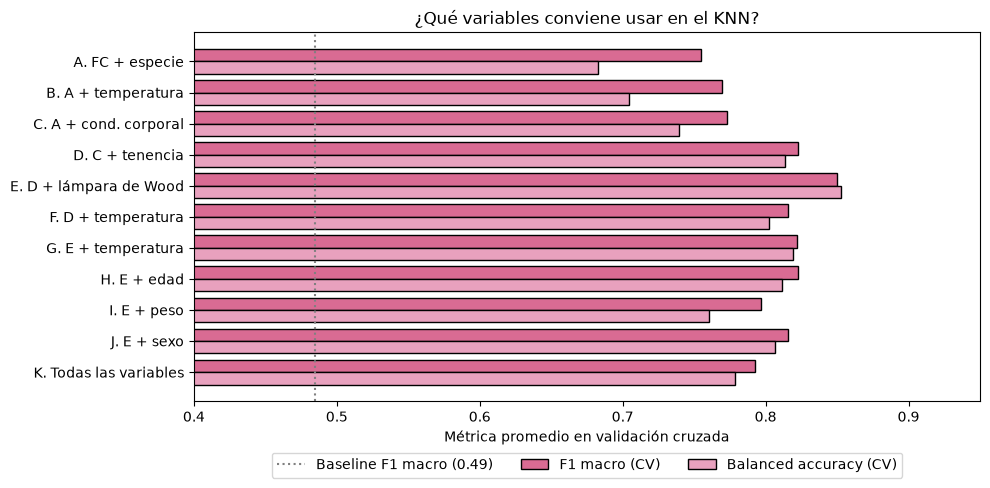

In [32]:
f1_base_cv = cross_val_score(DummyClassifier(strategy="most_frequent"), X_train, y_train,
                             cv=cv, scoring="f1_macro").mean()

fig, ax = plt.subplots(figsize=(10, 5))
pos = np.arange(len(tabla))
ax.barh(pos - 0.2, tabla["F1 macro (CV)"], height=0.4, color=ROSA, edgecolor="black", label="F1 macro (CV)")
ax.barh(pos + 0.2, tabla["balanced acc (CV)"], height=0.4, color=ROSA_CLARO, edgecolor="black", label="Balanced accuracy (CV)")
ax.axvline(f1_base_cv, color="gray", linestyle=":", label=f"Baseline F1 macro ({f1_base_cv:.2f})")
ax.set_yticks(pos)
ax.set_yticklabels(tabla.index)
ax.invert_yaxis()
ax.set_xlim(0.4, 0.95)
ax.set_xlabel("Métrica promedio en validación cruzada")
ax.set_title("¿Qué variables conviene usar en el KNN?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout()
plt.show()

**Cómo leer la tabla:**

- **La base (A) ya supera al baseline** (F1 macro ≈ 0,76 vs 0,49), pero con un recall de "sano" bajo.
- **Sumar condición corporal (C) y tenencia (D) mejora de forma clara**, y **sumar la lámpara de Wood (E)** da el mejor resultado de todos: F1 macro ≈ 0,85 y balanced accuracy ≈ 0,85.
- **La temperatura no ayuda:** B, F y G quedan por debajo de sus equivalentes sin temperatura. Coincide con el EDA: las distribuciones de sanos y enfermos se superponen casi por completo. Hacía falta comprobar que "combinada con otras variables" tampoco aporta, y los datos dicen que no.
- **Edad, peso y sexo tampoco ayudan:** sumar cualquiera de ellas al conjunto E (H, I, J) hace **bajar** el F1 macro (de 0,85 a 0,82, 0,80 y 0,82). El peso es la que más perjudica, probablemente porque en caninos varía muchísimo entre razas sin relación con la salud, y eso "aleja" a pacientes que en lo demás son parecidos.
- **Usar todas las variables (K) empeora:** en KNN **más variables no es mejor**, porque cada variable irrelevante agrega ruido al cálculo de distancias.
- **Cautela:** el desvío entre folds es ≈ 0,04, así que diferencias de 0,01-0,02 (por ejemplo D vs F, o H vs J) no son concluyentes. Lo que sí es claro es el orden general: *base < +condición corporal < +tenencia < +Wood*, y que ninguna de las demás variables mejora a E.

Por último, comprobamos si la **raza** (que el EDA solo describió, sin relacionarla con la salud) aporta algo al mejor conjunto:

In [33]:
# ¿Aporta algo la raza? (13 razas -> 12 columnas 0/1 extra)
X_train_raza = X_train[conjuntos["E. D + lámpara de Wood"]].join(RAZAS.loc[X_train.index])

gs_raza = GridSearchCV(Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier())]),
                       {"knn__n_neighbors": K_GRID}, cv=cv, scoring="f1_macro")
gs_raza.fit(X_train_raza, y_train)

print(f"Conjunto E sin raza: F1 macro CV = {tabla.loc['E. D + lámpara de Wood', 'F1 macro (CV)']:.3f}")
print(f"Conjunto E + raza:   F1 macro CV = {gs_raza.best_score_:.3f}")

Conjunto E sin raza: F1 macro CV = 0.850
Conjunto E + raza:   F1 macro CV = 0.844


Agregar la raza **no mejora** (incluso baja un poco): suma 12 dimensiones que solo distorsionan las distancias. La dejamos afuera.

**Variables elegidas (conjunto E):** frecuencia cardíaca, especie, condición corporal, condición de tenencia (rescued / lost_rescued) y resultado de la lámpara de Wood.

# 7. Modelo final: elección de k y evaluación en test

### 7.1 Curva de validación de k (solo con train)

Conjunto elegido: E. D + lámpara de Wood
Variables: ['frec_cardiaca', 'felino', 'condicion_corporal', 'rescued', 'lost_rescued', 'wood_positivo']
Mejor k: 15  |  F1 macro (CV): 0.850


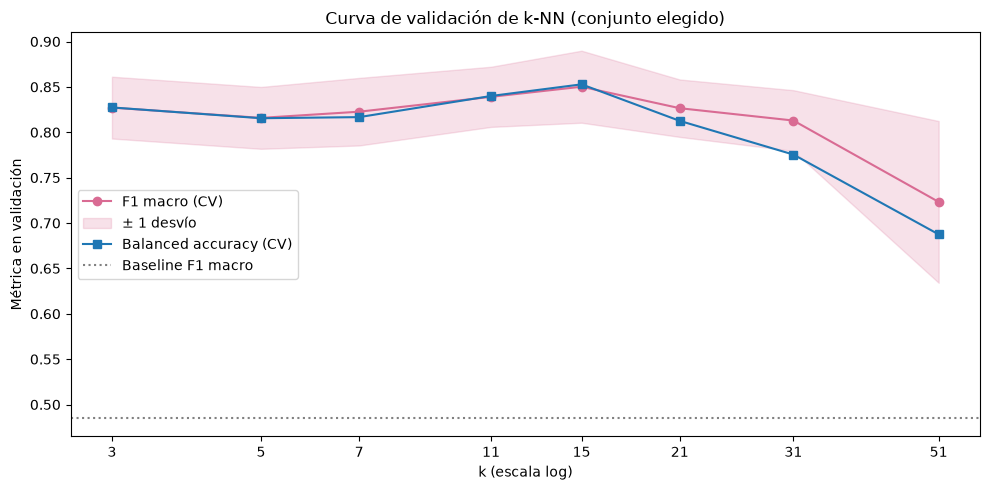

In [34]:
mejor = tabla["F1 macro (CV)"].idxmax()
gs = busquedas[mejor]
cols_final = conjuntos[mejor]
k_final = gs.best_params_["knn__n_neighbors"]
print(f"Conjunto elegido: {mejor}")
print(f"Variables: {cols_final}")
print(f"Mejor k: {k_final}  |  F1 macro (CV): {gs.best_score_:.3f}")

res = pd.DataFrame(gs.cv_results_)
k_vals = res["param_knn__n_neighbors"].astype(int)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_vals, res["mean_test_f1_macro"], marker="o", color=ROSA, label="F1 macro (CV)")
ax.fill_between(k_vals, res["mean_test_f1_macro"] - res["std_test_f1_macro"],
                res["mean_test_f1_macro"] + res["std_test_f1_macro"], color=ROSA, alpha=0.2, label="± 1 desvío")
ax.plot(k_vals, res["mean_test_balanced_accuracy"], marker="s", color="tab:blue", label="Balanced accuracy (CV)")
ax.axhline(f1_base_cv, color="gray", linestyle=":", label="Baseline F1 macro")
ax.set_xscale("log")
ax.set_xticks(k_vals)
ax.set_xticklabels(k_vals)
ax.minorticks_off()
ax.set_xlabel("k (escala log)")
ax.set_ylabel("Métrica en validación")
ax.set_title("Curva de validación de k-NN (conjunto elegido)")
ax.legend(loc="center left")
plt.tight_layout()
plt.show()

- Con **k chico** (3-7) el F1 macro es algo menor (≈ 0,82-0,83): el modelo depende de pocos vecinos y copia su ruido.
- Con **k grande** la curva cae, y en k = 51 lo hace fuerte: hay solo 93 sanos en train y con tantos vecinos los sanos quedan "ahogados" por los enfermos (el modelo tiende a la clase mayoritaria, es decir, subajuste).
- **k = 15** es el punto donde la curva alcanza su máximo (k = 11 queda muy cerca).

### 7.2 Evaluación en test (una sola vez)

,modelo,accuracy,balanced accuracy,F1 macro,recall sano,recall enfermo
0,Baseline (siempre 'enfermo'),0.942,0.500,0.485,0.000,1.000
1,"KNN k=5, todas las variables",0.945,0.746,0.746,0.522,0.971
2,"KNN final (k=15, conjunto E)",0.972,0.883,0.876,0.783,0.984


              precision    recall  f1-score   support

        sano      0.750     0.783     0.766        23
     enfermo      0.987     0.984     0.985       377

    accuracy                          0.973       400
   macro avg      0.868     0.883     0.876       400
weighted avg      0.973     0.973     0.973       400



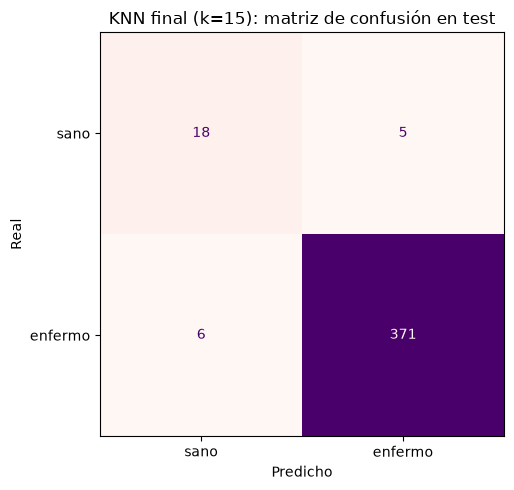

In [35]:
modelo_final = gs.best_estimator_            # ya reentrenado con todo train
pred_final = modelo_final.predict(X_test[cols_final])

resultados.append(metricas(f"KNN final (k={k_final}, conjunto {mejor[0]})", y_test, pred_final))
display(pd.DataFrame(resultados).round(3))

print(classification_report(y_test, pred_final, labels=ORDEN, digits=3))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_final, labels=ORDEN, ax=ax, cmap="RdPu", colorbar=False)
ax.set_title(f"KNN final (k={k_final}): matriz de confusión en test")
ax.set_xlabel("Predicho")
ax.set_ylabel("Real")
plt.tight_layout()
plt.show()

**Resultado:** el modelo final pasa de 94,3 % (baseline) a **97,5 % de accuracy**, y sobre todo **detecta a los sanos** (recall de "sano" ≈ 0,83 contra 0 del baseline) con un F1 macro de ≈ 0,89 contra 0,49.

> **Cuidado al interpretar:** en test hay solo 23 sanos. "19 de 23" es una estimación poco precisa: su intervalo de confianza del 95 % va aproximadamente de 0,63 a 0,93. La estimación más estable es la de **validación cruzada** (F1 macro ≈ 0,85); el test sirve como confirmación independiente de que no hubo sobreajuste al elegir variables y k.

### 7.3 ¿En qué casos se equivoca?

In [36]:
errores = X_test[cols_final].copy()
errores["real"] = y_test
errores["predicho"] = pred_final
errores = errores[errores["real"] != errores["predicho"]]

errores["especie"] = df_ml.loc[errores.index, "especie"]
errores["tenencia"] = df_ml.loc[errores.index, "tenencia"]
errores["FC era nula (imputada)"] = df_ml.loc[errores.index, "frec_cardiaca"].isna()
errores["CC era nula (imputada)"] = df_ml.loc[errores.index, "condicion_corporal"].isna()

errores[["real", "predicho", "especie", "tenencia", "frec_cardiaca", "condicion_corporal",
         "wood_positivo", "FC era nula (imputada)", "CC era nula (imputada)"]].sort_values("real")

,real,predicho,especie,tenencia,frec_cardiaca,condicion_corporal,wood_positivo,FC era nula (imputada),CC era nula (imputada)
1201,enfermo,sano,canino,owned,86.0,3.0,0,False,False
231,enfermo,sano,canino,owned,87.0,3.0,0,False,False
1460,enfermo,sano,canino,owned,89.0,3.0,0,False,False
1499,enfermo,sano,canino,owned,96.0,3.0,0,False,False
1866,enfermo,sano,canino,owned,91.0,3.0,0,False,False
1320,enfermo,sano,canino,owned,97.0,3.0,0,False,False
1376,sano,enfermo,canino,owned,114.0,3.0,0,False,False
1511,sano,enfermo,canino,owned,75.0,3.0,0,False,False
534,sano,enfermo,canino,owned,80.0,3.0,0,False,False
1049,sano,enfermo,canino,owned,73.0,3.0,0,False,False


Los 10 errores (6 enfermos tomados por sanos y 4 sanos tomados por enfermos) tienen **exactamente el mismo perfil**: son **caninos con dueño, condición corporal 3 y lámpara de Wood negativa**. Ninguno tenía datos imputados, así que la imputación no explica los fallos.

Ese es justamente el único grupo donde sanos y enfermos son indistinguibles con las variables disponibles: la condición corporal 3 la tienen todos los sanos pero también ~21 % de los enfermos, y en caninos las frecuencias cardíacas se superponen (enfermos 66-137 lpm, sanos 73-117 lpm). El modelo no falla "al azar": falla donde los datos no contienen información para separar a las clases.

# 8. Conclusiones

**Sobre las variables (respuesta a la pregunta de selección):**

| Variable | Decisión | Motivo |
|---|---|---|
| Frecuencia cardíaca + especie | ✅ Incluir (siempre juntas) | La FC solo es informativa según la especie |
| Condición corporal | ✅ Incluir | Mejora el F1; ≥ 4 implica enfermo |
| Tenencia (rescued / lost_rescued) | ✅ Incluir | Rescatados casi siempre enfermos |
| Lámpara de Wood | ✅ Incluir | Positivo ⇒ enfermo (Ringworm); mejor conjunto en CV |
| Temperatura | ❌ Descartar | No aporta ni sola (B) ni combinada (F, G) |
| Edad, peso, sexo | ❌ Descartar | Sumarlas al conjunto E empeora el F1 macro (el peso es la que más) |
| Raza | ❌ Descartar | No mejora y suma 12 dimensiones |

**Sobre el modelo:** KNN (k = 15, con `StandardScaler` en un `Pipeline`) alcanza F1 macro ≈ 0,85 en validación cruzada y 97,5 % de accuracy en test, frente a 94,3 % del baseline, detectando ≈ 83 % de los sanos.

**Limitaciones que hay que declarar en el informe:**
1. Los patrones más fuertes (FC en felinos, condición corporal de los sanos, nulos solo en enfermos) parecen **artefactos de cómo se armó el dataset**; el desempeño **no es extrapolable** a pacientes reales.
2. Hay solo 116 sanos (5,8 %): las métricas sobre la clase "sano" tienen mucha incertidumbre.
3. La imputación de la Parte 2 (mediana global de la FC y antes del split) **debería corregirse** para que el informe del grupo sea consistente con esta parte.

# Anexo: ¿y si predecimos el diagnóstico exacto (13 clases)?

Para justificar la decisión de usar sano/enfermo, probamos el mismo KNN sobre los 13 diagnósticos (mismo split y mismas variables, con `k = 15`).

In [37]:
y13_train = df_ml.loc[X_train.index, "diagnostico"]
y13_test = df_ml.loc[X_test.index, "diagnostico"]

pipe13 = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=15))])
pipe13.fit(X_train, y13_train)
pred13 = pipe13.predict(X_test)

base13 = DummyClassifier(strategy="most_frequent").fit(X_train, y13_train).predict(X_test)
print(f"Accuracy KNN 13 clases: {accuracy_score(y13_test, pred13):.1%}   |   baseline: {accuracy_score(y13_test, base13):.1%}   |   azar puro: {1/13:.1%}")

recall13 = pd.Series(classification_report(y13_test, pred13, output_dict=True, zero_division=0)).drop(
    ["accuracy", "macro avg", "weighted avg"]).apply(lambda d: d["recall"])
print("\nRecall por diagnóstico:")
recall13.sort_values(ascending=False).round(2)

Accuracy KNN 13 clases: 22.2%   |   baseline: 9.2%   |   azar puro: 7.7%

Recall por diagnóstico:


healthy                                      0.83
Ringworm and Yeast Otitis                    0.78
Ringworm                                     0.37
Atopic Dermatitis and Bacterial Otitis       0.22
Bacterial Dermatitis and Bacterial Otitis    0.17
Ear Mites                                    0.14
Ear Mites and Yeast Otitis                   0.14
Yeast Dermatitis                             0.09
Yeast Otitis                                 0.08
Bacterial Otitis                             0.08
Bacterial Dermatitis                         0.06
Atopic Dermatitis                            0.03
Yeast Dermatitis and Yeast Otitis            0.00
dtype: float64

Con 13 clases el accuracy es de apenas ≈ 22 % (baseline 9 %): mejor que el azar, pero muy lejos de ser útil. Los únicos diagnósticos que se reconocen son *healthy* (por la condición corporal y la frecuencia cardíaca) y los dos que incluyen *Ringworm* (por la lámpara de Wood, que es positiva solo en ellos; aun así se confunden entre sí). Los otros 10 diagnósticos casi no se distinguen entre sí con los datos disponibles (recall ≤ 0,22). Por eso el modelo se plantea como **sano / enfermo**.

### Interpretación de Hallazgos y Análisis Temporal

* **Diagnósticos más frecuentes:** Los motivos de consulta más repetidos en la veterinaria son *Ear Mites and Yeast Otitis* (181 casos), *Ringworm and Yeast Otitis* (176 casos) y *Bacterial Dermatitis* (172 casos).
* **Diferencias entre grupos:** Los caninos concentran mayor volumen de casos totales (destacando en infecciones fúngicas y de ácaros), mientras que los felinos muestran una alta incidencia en *Yeast Dermatitis*.

#### Justificación sobre la Serie Temporal:
* **¿Es posible armar una serie temporal?** No. 
* **Motivo:** Las columnas de fecha (`intake date` y `booking date`) poseen una gran cantidad de valores faltantes (más de 800 y 1100 nulos respectivamente). Al unificarlas, todavía queda un porcentaje importante de registros sin fecha alguna, y la distribución temporal está fragmentada entre 2023, 2024 y 2025 sin una continuidad uniforme. Forzar una serie temporal introduciría sesgos graves, por lo que se decide descartar este enfoque analítico y focalizar el modelo predictivo en las características clínicas del paciente.